In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset
df = pd.read_csv("../data/housing.csv")

# Display first five rows
df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [2]:
# Dataset information
print("Dataset Shape:", df.shape)

df.info()

Dataset Shape: (20640, 10)
<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  str    
dtypes: float64(9), str(1)
memory usage: 1.6 MB


In [3]:
# Statistical summary
df.describe()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


# Real Estate Housing Price Prediction
### Ridge & Lasso Regression

**Objective:** Predict median house values using the California Housing dataset.

**Algorithms:**
- Ordinary Least Squares (OLS)
- Ridge Regression (L2)
- Lasso Regression (L1)

**Evaluation Metrics:**
- RMSE
- MAE
- R² Score

In [4]:
# Check missing values
missing_values = df.isnull().sum()

print("Missing Values:")
print(missing_values)

# Calculate missing percentages
missing_percentage = (df.isnull().sum() / len(df)) * 100

print("\nMissing Percentage:")
print(missing_percentage)

Missing Values:
longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64

Missing Percentage:
longitude             0.000000
latitude              0.000000
housing_median_age    0.000000
total_rooms           0.000000
total_bedrooms        1.002907
population            0.000000
households            0.000000
median_income         0.000000
median_house_value    0.000000
ocean_proximity       0.000000
dtype: float64


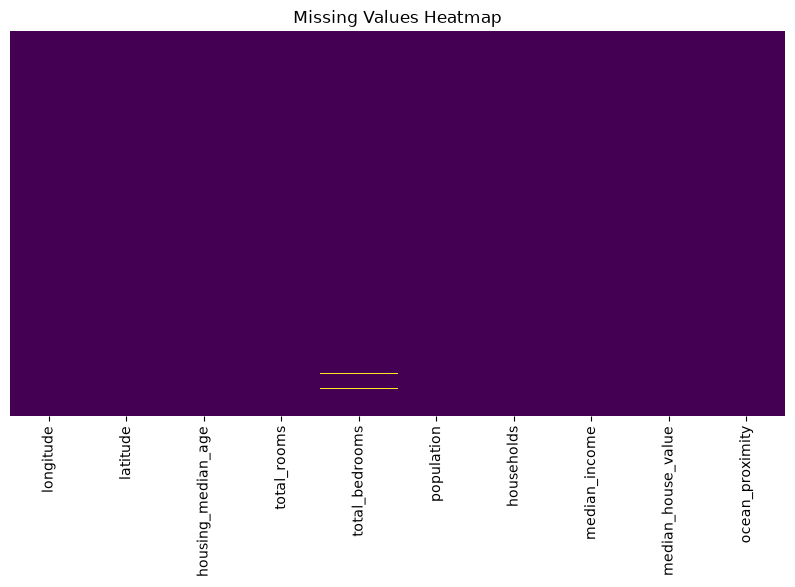

In [5]:
plt.figure(figsize=(10, 5))

sns.heatmap(
    df.isnull(),
    cbar=False,
    yticklabels=False,
    cmap="viridis"
)

plt.title("Missing Values Heatmap")
plt.show()

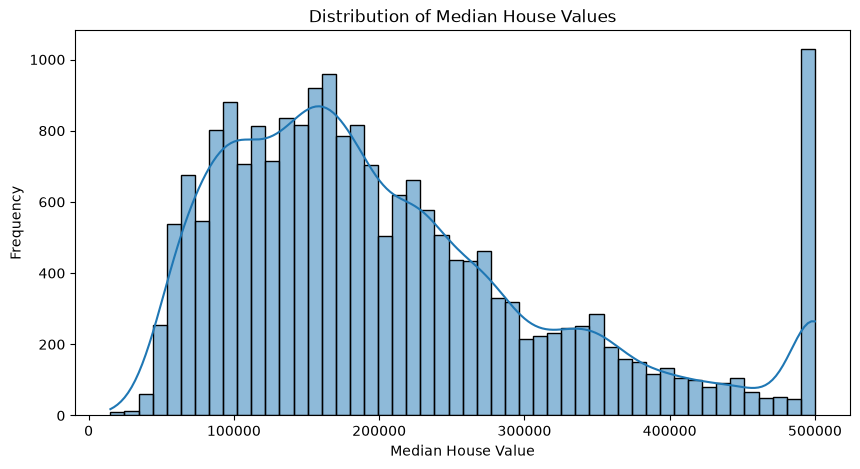

In [6]:
plt.figure(figsize=(10, 5))

sns.histplot(
    df["median_house_value"],
    bins=50,
    kde=True
)

plt.title("Distribution of Median House Values")
plt.xlabel("Median House Value")
plt.ylabel("Frequency")

plt.show()

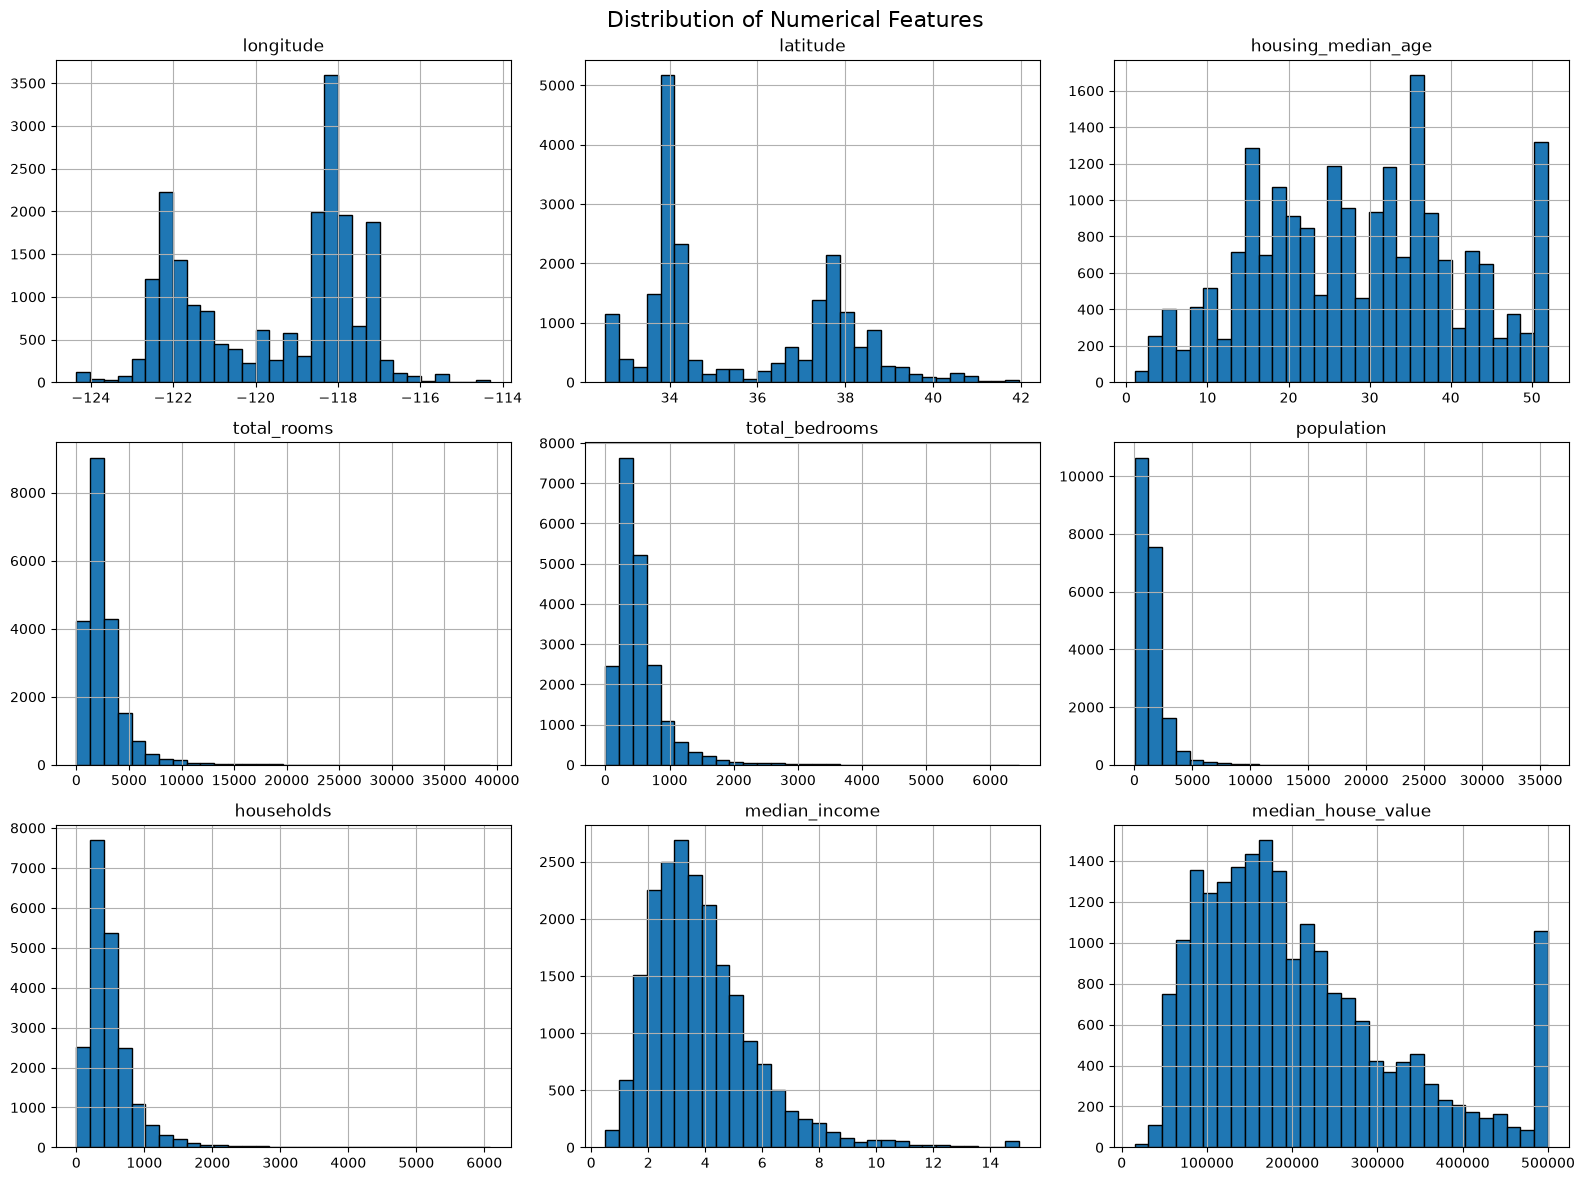

In [7]:
df.hist(figsize=(16, 12), bins=30, edgecolor="black")

plt.suptitle("Distribution of Numerical Features", fontsize=16)

plt.tight_layout()
plt.show()

In [8]:
print("Ocean Proximity Categories:")
print(df["ocean_proximity"].value_counts())

Ocean Proximity Categories:
ocean_proximity
<1H OCEAN     9136
INLAND        6551
NEAR OCEAN    2658
NEAR BAY      2290
ISLAND           5
Name: count, dtype: int64


## Data Exploration and Missing Value Analysis

**Objective:** Explore the dataset, identify missing values, and understand feature distributions.

**Key Findings:**
- Identified missing values in `total_bedrooms`.
- Examined the distribution of median house values.
- Visualized numerical feature distributions.
- Identified the unique categories in `ocean_proximity`.
- Observed the overall characteristics of the dataset.

**Conclusion:**

The exploratory data analysis revealed missing values and different feature distributions. These findings will help guide the data preprocessing and feature engineering stages.

In [9]:
# Select numerical features
numerical_df = df.select_dtypes(include=[np.number])

# Calculate correlation matrix
correlation_matrix = numerical_df.corr()

# Display correlation with target variable
target_correlation = correlation_matrix["median_house_value"].sort_values(
    ascending=False
)

print("Correlation with Median House Value:")
print(target_correlation)

Correlation with Median House Value:
median_house_value    1.000000
median_income         0.688075
total_rooms           0.134153
housing_median_age    0.105623
households            0.065843
total_bedrooms        0.049686
population           -0.024650
longitude            -0.045967
latitude             -0.144160
Name: median_house_value, dtype: float64


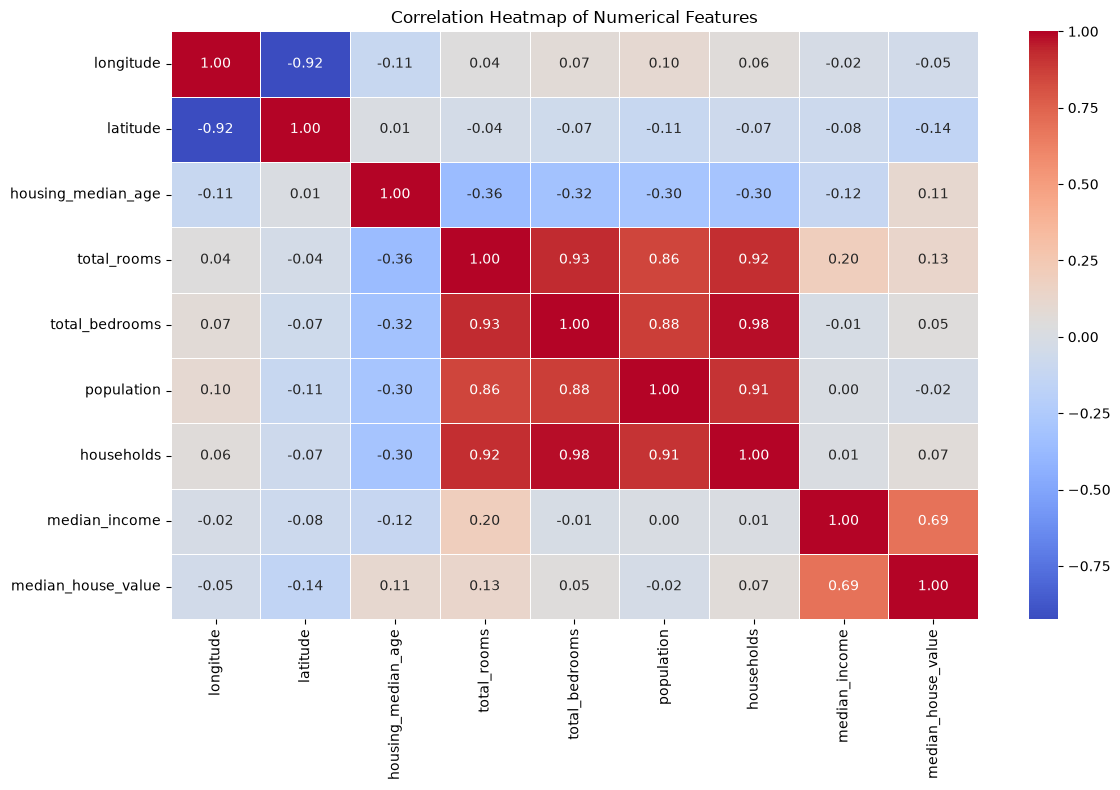

In [10]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Numerical Features")
plt.tight_layout()
plt.show()

In [11]:
# Extract upper triangle of correlation matrix
upper_triangle = correlation_matrix.where(
    np.triu(np.ones(correlation_matrix.shape), k=1).astype(bool)
)

# Find feature pairs with correlation greater than 0.7
high_correlation = (
    upper_triangle.stack()
    .reset_index()
)

high_correlation.columns = ["Feature 1", "Feature 2", "Correlation"]

high_correlation = high_correlation[
    high_correlation["Correlation"].abs() > 0.7
]

print("Highly Correlated Feature Pairs:")
print(high_correlation)

Highly Correlated Feature Pairs:
         Feature 1       Feature 2  Correlation
1        longitude        latitude    -0.924664
31     total_rooms  total_bedrooms     0.930380
32     total_rooms      population     0.857126
33     total_rooms      households     0.918484
41  total_bedrooms      population     0.877747
42  total_bedrooms      households     0.979728
51      population      households     0.907222


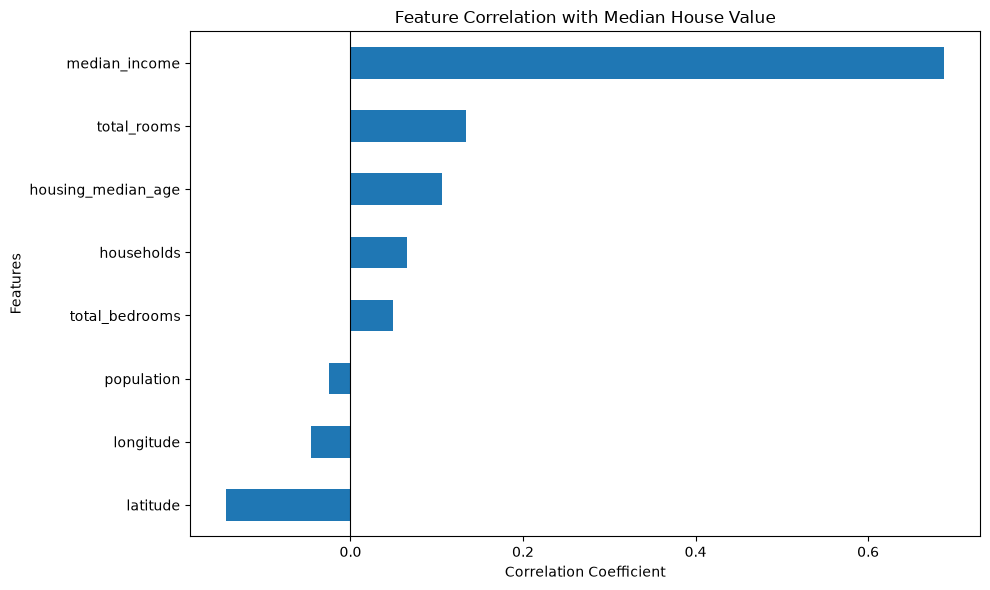

In [12]:
target_corr = correlation_matrix["median_house_value"].drop(
    "median_house_value"
).sort_values()

plt.figure(figsize=(10, 6))

target_corr.plot(kind="barh")

plt.title("Feature Correlation with Median House Value")
plt.xlabel("Correlation Coefficient")
plt.ylabel("Features")
plt.axvline(x=0, color="black", linewidth=0.8)

plt.tight_layout()
plt.show()

## Correlation and Multicollinearity Analysis

**Objective:** Examine relationships between numerical features and identify potential multicollinearity.

**Key Findings:**
- Calculated the Pearson correlation matrix for numerical features.
- Visualized feature relationships using a correlation heatmap.
- Identified highly correlated feature pairs using a correlation threshold of 0.7.
- Examined the correlation between numerical features and the target variable, `median_house_value`.

**Conclusion:**

Correlation analysis helps identify relationships between features and potential multicollinearity. Regularization techniques such as Ridge and Lasso will be used later to reduce the impact of multicollinearity on regression models.

In [13]:
# Create a copy of the original dataset
df_engineered = df.copy()

# Create interaction features
df_engineered["income_rooms_interaction"] = (
    df_engineered["median_income"] *
    df_engineered["total_rooms"]
)

df_engineered["income_bedrooms_interaction"] = (
    df_engineered["median_income"] *
    df_engineered["total_bedrooms"]
)

df_engineered["rooms_households_interaction"] = (
    df_engineered["total_rooms"] *
    df_engineered["households"]
)

# Display new features
df_engineered.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity,income_rooms_interaction,income_bedrooms_interaction,rooms_households_interaction
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY,7326.1760,1073.9508,110880.0
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY,58931.6386,9181.3484,8078662.0
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY,10646.6058,1378.9060,259659.0
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY,7189.3094,1326.1285,279006.0
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY,6257.7674,1076.9360,421393.0


In [14]:
# Calculate average rooms per household
df_engineered["rooms_per_household"] = (
    df_engineered["total_rooms"] /
    df_engineered["households"]
)

# Calculate average bedrooms per household
df_engineered["bedrooms_per_household"] = (
    df_engineered["total_bedrooms"] /
    df_engineered["households"]
)

# Calculate bedrooms-to-rooms ratio
df_engineered["bedrooms_ratio"] = (
    df_engineered["total_bedrooms"] /
    df_engineered["total_rooms"]
)

df_engineered.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity,income_rooms_interaction,income_bedrooms_interaction,rooms_households_interaction,rooms_per_household,bedrooms_per_household,bedrooms_ratio
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY,7326.1760,1073.9508,110880.0,6.984127,1.023810,0.146591
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY,58931.6386,9181.3484,8078662.0,6.238137,0.971880,0.155797
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY,10646.6058,1378.9060,259659.0,8.288136,1.073446,0.129516
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY,7189.3094,1326.1285,279006.0,5.817352,1.073059,0.184458
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY,6257.7674,1076.9360,421393.0,6.281853,1.081081,0.172096


In [15]:
# Replace infinite values with NaN
df_engineered.replace(
    [np.inf, -np.inf],
    np.nan,
    inplace=True
)

# Check missing values in engineered features
print("Missing Values After Feature Engineering:")
print(df_engineered.isnull().sum())

Missing Values After Feature Engineering:
longitude                         0
latitude                          0
housing_median_age                0
total_rooms                       0
total_bedrooms                  207
population                        0
households                        0
median_income                     0
median_house_value                0
ocean_proximity                   0
income_rooms_interaction          0
income_bedrooms_interaction     207
rooms_households_interaction      0
rooms_per_household               0
bedrooms_per_household          207
bedrooms_ratio                  207
dtype: int64


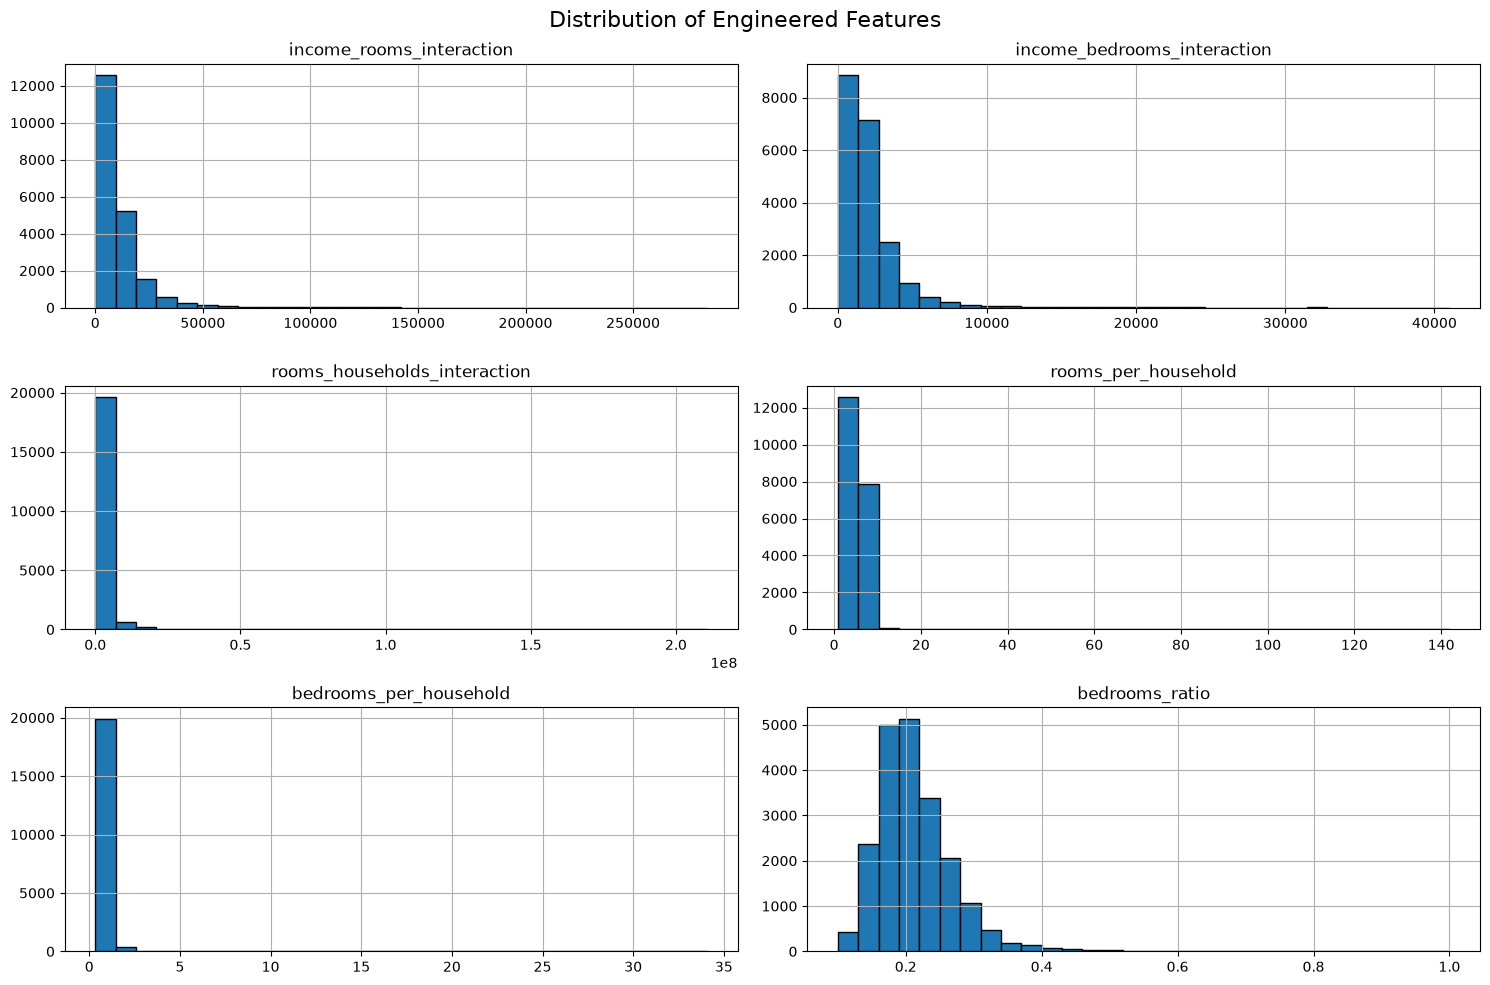

In [16]:
interaction_features = [
    "income_rooms_interaction",
    "income_bedrooms_interaction",
    "rooms_households_interaction",
    "rooms_per_household",
    "bedrooms_per_household",
    "bedrooms_ratio"
]

df_engineered[interaction_features].hist(
    figsize=(15, 10),
    bins=30,
    edgecolor="black"
)

plt.suptitle("Distribution of Engineered Features", fontsize=16)
plt.tight_layout()
plt.show()

## Feature Engineering

**Objective:** Create interaction and ratio features to improve the predictive information available to regression models.

**Key Findings:**
- Created interaction features by combining existing numerical variables.
- Generated ratio features to represent household and housing characteristics.
- Handled infinite values resulting from division operations.
- Visualized the distributions of newly engineered features.

**Conclusion:**

Feature engineering introduced additional information that may improve model performance. The new features will be evaluated during model training to determine their effectiveness in predicting median house values.

In [17]:
# Separate features and target
X = df_engineered.drop("median_house_value", axis=1)
y = df_engineered["median_house_value"]

print("Feature Shape:", X.shape)
print("Target Shape:", y.shape)

Feature Shape: (20640, 15)
Target Shape: (20640,)


In [18]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

Training Features: (16512, 15)
Testing Features: (4128, 15)


In [19]:
# Identify numerical and categorical columns
numerical_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Numerical Features:", numerical_features)
print("\nCategorical Features:", categorical_features)

Numerical Features: ['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', 'income_rooms_interaction', 'income_bedrooms_interaction', 'rooms_households_interaction', 'rooms_per_household', 'bedrooms_per_household', 'bedrooms_ratio']

Categorical Features: ['ocean_proximity']


C:\Users\Lenovo\AppData\Local\Temp\ipykernel_21912\898612773.py:6: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X_train.select_dtypes(


In [20]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Numerical preprocessing
numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing pipelines
preprocessor = ColumnTransformer([
    ("num", numerical_pipeline, numerical_features),
    ("cat", categorical_pipeline, categorical_features)
])

print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


In [21]:
# Fit on training data and transform
X_train_processed = preprocessor.fit_transform(X_train)

# Transform testing data using the same fitted pipeline
X_test_processed = preprocessor.transform(X_test)

print("Processed Training Shape:", X_train_processed.shape)
print("Processed Testing Shape:", X_test_processed.shape)

Processed Training Shape: (16512, 19)
Processed Testing Shape: (4128, 19)


In [22]:
# Check missing values after preprocessing
print(
    "Missing values in training data:",
    np.isnan(X_train_processed).sum()
)

print(
    "Missing values in testing data:",
    np.isnan(X_test_processed).sum()
)

Missing values in training data: 0
Missing values in testing data: 0


In [23]:
if hasattr(X_train_processed, "toarray"):
    X_train_processed = X_train_processed.toarray()

if hasattr(X_test_processed, "toarray"):
    X_test_processed = X_test_processed.toarray()

print("Training missing values:", np.isnan(X_train_processed).sum())
print("Testing missing values:", np.isnan(X_test_processed).sum())

Training missing values: 0
Testing missing values: 0


## Data Preprocessing and Standardization

**Objective:** Prepare the dataset for regression modeling by handling missing values, encoding categorical variables, and standardizing numerical features.

**Key Findings:**
- Separated input features and the target variable.
- Split the dataset into 80% training and 20% testing data.
- Applied median imputation to numerical features.
- Applied most-frequent imputation to categorical features.
- Encoded categorical variables using One-Hot Encoding.
- Standardized numerical features using StandardScaler.
- Verified that the processed datasets contain no missing values.

**Conclusion:**

The preprocessing pipeline successfully prepared the dataset for regression modeling. Fitting preprocessing transformations only on training data helps prevent data leakage and ensures consistent transformations on testing data.

In [24]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso

print("Regression models imported successfully.")

Regression models imported successfully.


In [25]:
# Initialize OLS model
ols_model = LinearRegression()

# Train model
ols_model.fit(X_train_processed, y_train)

# Generate predictions
ols_predictions = ols_model.predict(X_test_processed)

print("OLS Regression trained successfully.")

OLS Regression trained successfully.


In [26]:
# Initialize Ridge model
ridge_model = Ridge(alpha=1.0)

# Train model
ridge_model.fit(X_train_processed, y_train)

# Generate predictions
ridge_predictions = ridge_model.predict(X_test_processed)

print("Ridge Regression trained successfully.")

Ridge Regression trained successfully.


In [27]:
# Initialize Lasso model
lasso_model = Lasso(alpha=1.0, max_iter=10000)

# Train model
lasso_model.fit(X_train_processed, y_train)

# Generate predictions
lasso_predictions = lasso_model.predict(X_test_processed)

print("Lasso Regression trained successfully.")

Lasso Regression trained successfully.


In [28]:
# Get processed feature names
feature_names = preprocessor.get_feature_names_out()

# Create coefficient comparison
coefficient_comparison = pd.DataFrame({
    "Feature": feature_names,
    "OLS": ols_model.coef_,
    "Ridge": ridge_model.coef_,
    "Lasso": lasso_model.coef_
})

coefficient_comparison.head(15)

,Feature,OLS,Ridge,Lasso
0,num__longitude,-54742.179961,-54699.740892,-54730.167962
1,num__latitude,-54907.126860,-54868.791283,-54897.596684
2,num__housing_median_age,14758.656400,14760.668338,14755.121085
3,num__total_rooms,2541.502701,2373.196425,2419.893212
4,num__total_bedrooms,1165.199932,1443.189198,1282.558072
5,num__population,-42189.972919,-42168.542437,-42183.612129
6,num__households,33955.228681,33821.119961,33943.888878
7,num__median_income,73025.777904,73021.772102,73025.325793
8,num__income_rooms_interaction,-18958.196030,-18697.930256,-18787.779234
9,num__income_bedrooms_interaction,32995.938025,32764.103874,32844.937923


In [29]:
# Count non-zero coefficients
ols_nonzero = np.count_nonzero(ols_model.coef_)
ridge_nonzero = np.count_nonzero(ridge_model.coef_)
lasso_nonzero = np.count_nonzero(lasso_model.coef_)

print("Non-zero Coefficients:")
print("OLS:", ols_nonzero)
print("Ridge:", ridge_nonzero)
print("Lasso:", lasso_nonzero)

Non-zero Coefficients:
OLS: 19
Ridge: 19
Lasso: 18


## Regression Model Training

**Objective:** Train and examine OLS, Ridge, and Lasso regression models using the preprocessed California Housing dataset.

**Key Findings:**
- Trained an Ordinary Least Squares (OLS) regression model.
- Trained a Ridge regression model with L2 regularization.
- Trained a Lasso regression model with L1 regularization.
- Generated predictions using the testing dataset.
- Compared model coefficients to examine the effect of regularization.
- Analyzed non-zero coefficients to understand Lasso feature selection.

**Conclusion:**

Three regression models were successfully trained. Ridge and Lasso introduce regularization to control model complexity and potentially improve generalization. Their performance will be further evaluated using hyperparameter tuning and regression metrics.

In [30]:
from sklearn.linear_model import Ridge, Lasso, LinearRegression
from sklearn.model_selection import GridSearchCV

print("All required models imported successfully!")

All required models imported successfully!


In [31]:
alpha_values = {
    "alpha": [0.001, 0.01, 0.1, 1, 10, 100, 1000]
}

print("Alpha values:", alpha_values["alpha"])

Alpha values: [0.001, 0.01, 0.1, 1, 10, 100, 1000]


In [32]:
ridge_grid = GridSearchCV(
    estimator=Ridge(),
    param_grid=alpha_values,
    cv=5,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1,
    verbose=1
)

# Train using cross-validation
ridge_grid.fit(X_train_processed, y_train)

print("Best Ridge Alpha:", ridge_grid.best_params_)
print("Best Ridge CV RMSE:", -ridge_grid.best_score_)

Fitting 5 folds for each of 7 candidates, totalling 35 fits
Best Ridge Alpha: {'alpha': 1}
Best Ridge CV RMSE: 67729.33200441024


In [33]:
lasso_grid = GridSearchCV(
    estimator=Lasso(max_iter=50000),
    param_grid=alpha_values,
    cv=5,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1,
    verbose=1
)

# Train using cross-validation
lasso_grid.fit(X_train_processed, y_train)

print("Best Lasso Alpha:", lasso_grid.best_params_)
print("Best Lasso CV RMSE:", -lasso_grid.best_score_)

Fitting 5 folds for each of 7 candidates, totalling 35 fits
Best Lasso Alpha: {'alpha': 10}
Best Lasso CV RMSE: 67726.86855954204


In [34]:
# Retrieve best models
best_ridge_model = ridge_grid.best_estimator_
best_lasso_model = lasso_grid.best_estimator_

# Generate predictions
best_ridge_predictions = best_ridge_model.predict(X_test_processed)
best_lasso_predictions = best_lasso_model.predict(X_test_processed)

print("Optimized models are ready.")

Optimized models are ready.


In [35]:
tuning_results = pd.DataFrame({
    "Model": ["Ridge", "Lasso"],
    "Best Alpha": [
        ridge_grid.best_params_["alpha"],
        lasso_grid.best_params_["alpha"]
    ],
    "Best CV RMSE": [
        -ridge_grid.best_score_,
        -lasso_grid.best_score_
    ]
})

tuning_results

,Model,Best Alpha,Best CV RMSE
0,Ridge,1,67729.332004
1,Lasso,10,67726.868560


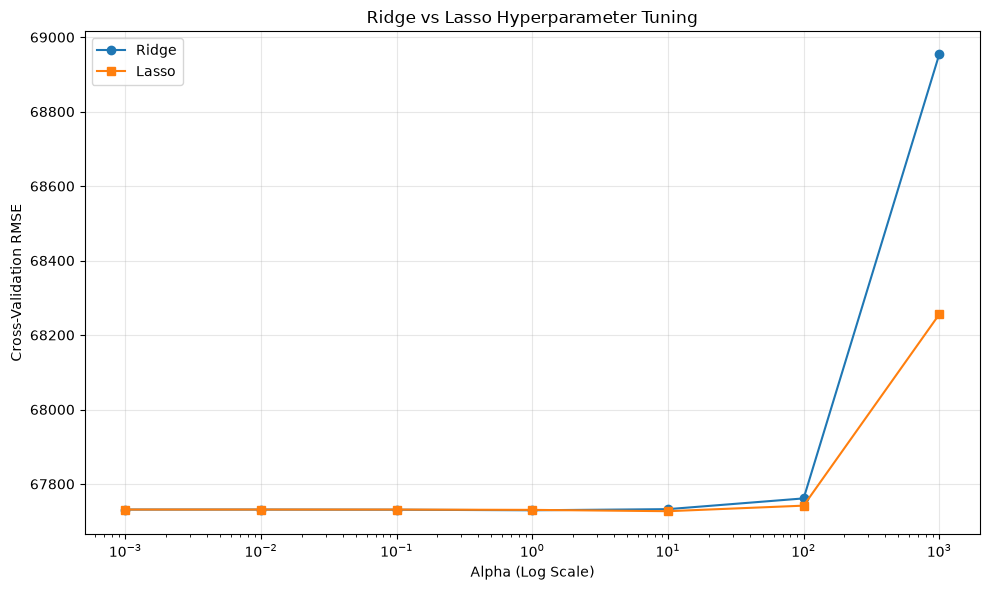

In [36]:
ridge_results = pd.DataFrame(ridge_grid.cv_results_)
lasso_results = pd.DataFrame(lasso_grid.cv_results_)

plt.figure(figsize=(10, 6))

plt.plot(
    ridge_results["param_alpha"].astype(float),
    -ridge_results["mean_test_score"],
    marker="o",
    label="Ridge"
)

plt.plot(
    lasso_results["param_alpha"].astype(float),
    -lasso_results["mean_test_score"],
    marker="s",
    label="Lasso"
)

plt.xscale("log")
plt.xlabel("Alpha (Log Scale)")
plt.ylabel("Cross-Validation RMSE")
plt.title("Ridge vs Lasso Hyperparameter Tuning")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## Hyperparameter Tuning

**Objective:** Optimize Ridge and Lasso regression models using GridSearchCV.

**Key Findings:**
- Evaluated seven alpha values for Ridge and Lasso regression.
- Applied 5-fold cross-validation.
- Used negative Root Mean Squared Error as the scoring metric.
- Identified the best alpha value for each regularized model.
- Retrieved optimized models and generated predictions.
- Visualized cross-validation RMSE across different alpha values.

**Conclusion:**

GridSearchCV identified the optimal regularization strengths for Ridge and Lasso regression among the tested alpha values. The optimized models are ready for final evaluation using the testing dataset.

In [37]:
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

print("Evaluation metrics imported successfully.")

Evaluation metrics imported successfully.


In [38]:
# OLS predictions
ols_predictions = ols_model.predict(X_test_processed)

# Optimized Ridge predictions
best_ridge_predictions = best_ridge_model.predict(X_test_processed)

# Optimized Lasso predictions
best_lasso_predictions = best_lasso_model.predict(X_test_processed)

print("All model predictions generated successfully.")

All model predictions generated successfully.


In [39]:
# Function to evaluate regression models
def evaluate_model(y_true, y_pred):
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)

    return rmse, mae, r2


# Evaluate OLS
ols_rmse, ols_mae, ols_r2 = evaluate_model(
    y_test, ols_predictions
)

# Evaluate Ridge
ridge_rmse, ridge_mae, ridge_r2 = evaluate_model(
    y_test, best_ridge_predictions
)

# Evaluate Lasso
lasso_rmse, lasso_mae, lasso_r2 = evaluate_model(
    y_test, best_lasso_predictions
)

print("Model evaluation completed successfully.")

Model evaluation completed successfully.


In [40]:
# Create comparison dataframe
model_comparison = pd.DataFrame({
    "Model": ["OLS", "Ridge", "Lasso"],
    "RMSE": [ols_rmse, ridge_rmse, lasso_rmse],
    "MAE": [ols_mae, ridge_mae, lasso_mae],
    "R2 Score": [ols_r2, ridge_r2, lasso_r2]
})

model_comparison = model_comparison.sort_values(
    by="RMSE"
).reset_index(drop=True)

model_comparison

,Model,RMSE,MAE,R2 Score
0,OLS,68946.950722,49586.768688,0.637237
1,Ridge,68956.268210,49594.152957,0.637139
2,Lasso,68956.969953,49590.116949,0.637131


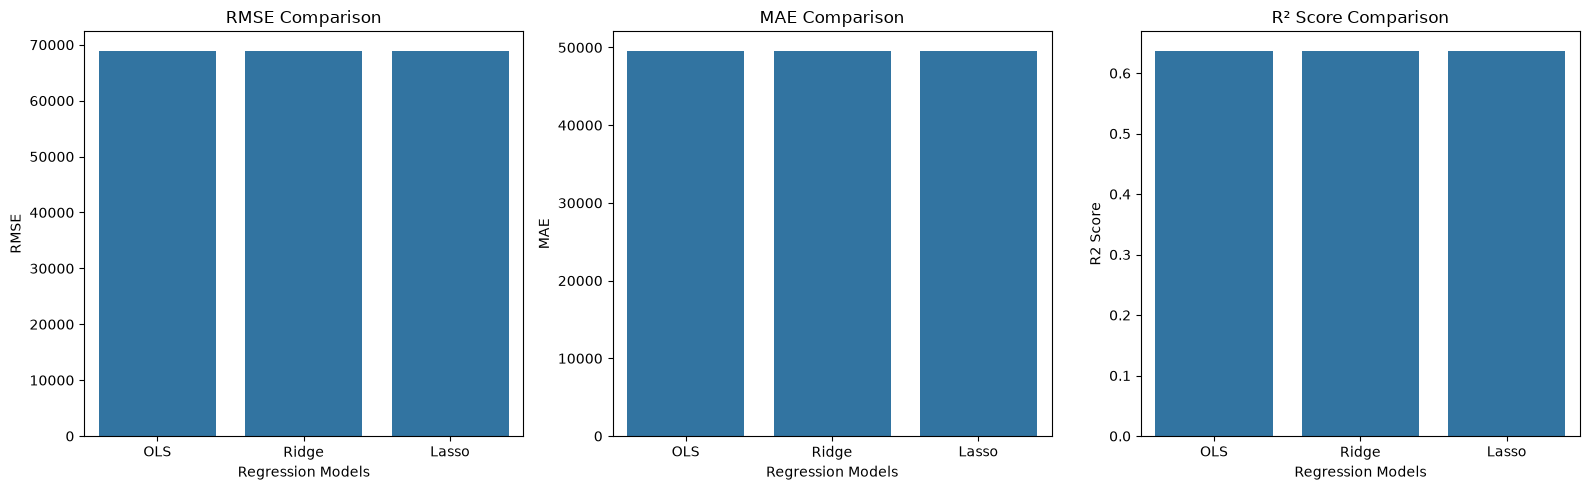

In [41]:
# Plot RMSE, MAE, and R2
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

metrics = ["RMSE", "MAE", "R2 Score"]
titles = [
    "RMSE Comparison",
    "MAE Comparison",
    "R² Score Comparison"
]

for ax, metric, title in zip(axes, metrics, titles):
    sns.barplot(
        data=model_comparison,
        x="Model",
        y=metric,
        ax=ax
    )

    ax.set_title(title)
    ax.set_xlabel("Regression Models")
    ax.set_ylabel(metric)

plt.tight_layout()
plt.show()

In [42]:
best_model_row = model_comparison.loc[
    model_comparison["RMSE"].idxmin()
]

print("Best Performing Model:", best_model_row["Model"])
print("RMSE:", best_model_row["RMSE"])
print("MAE:", best_model_row["MAE"])
print("R2 Score:", best_model_row["R2 Score"])

Best Performing Model: OLS
RMSE: 68946.95072174494
MAE: 49586.768688246724
R2 Score: 0.6372367640362099


## Regression Model Evaluation

**Objective:** Evaluate and compare OLS, Ridge, and Lasso regression models using RMSE, MAE, and R².

**Key Findings:**
- Evaluated three regression models using the testing dataset.
- Calculated Root Mean Squared Error (RMSE).
- Calculated Mean Absolute Error (MAE).
- Calculated R² scores to measure model performance.
- Compared model performance using a results table and bar charts.
- Identified the best-performing model based on the lowest RMSE.

**Conclusion:**

The evaluation results provide a quantitative comparison of OLS, Ridge, and Lasso regression models. The model with the lowest RMSE and MAE and the highest R² generally demonstrates better predictive performance. Residual analysis will provide further insight into prediction errors and model fit.

In [43]:
# Generate predictions
ols_predictions = ols_model.predict(X_test_processed)

ridge_predictions = best_ridge_model.predict(X_test_processed)

lasso_predictions = best_lasso_model.predict(X_test_processed)

print("Predictions generated successfully!")

Predictions generated successfully!


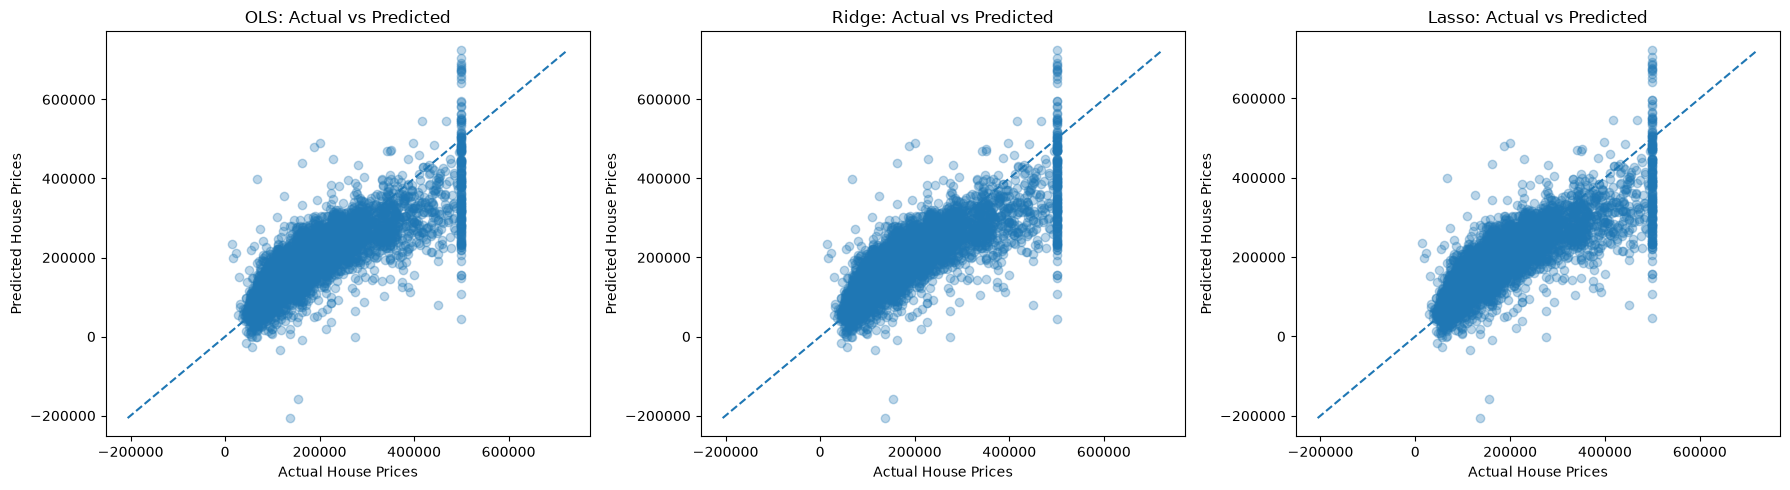

In [44]:
import matplotlib.pyplot as plt

predictions = {
    "OLS": ols_predictions,
    "Ridge": ridge_predictions,
    "Lasso": lasso_predictions
}

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (name, y_pred) in zip(axes, predictions.items()):
    ax.scatter(y_test, y_pred, alpha=0.3)

    min_value = min(y_test.min(), y_pred.min())
    max_value = max(y_test.max(), y_pred.max())

    ax.plot(
        [min_value, max_value],
        [min_value, max_value],
        linestyle="--"
    )

    ax.set_title(f"{name}: Actual vs Predicted")
    ax.set_xlabel("Actual House Prices")
    ax.set_ylabel("Predicted House Prices")

plt.tight_layout()
plt.show()

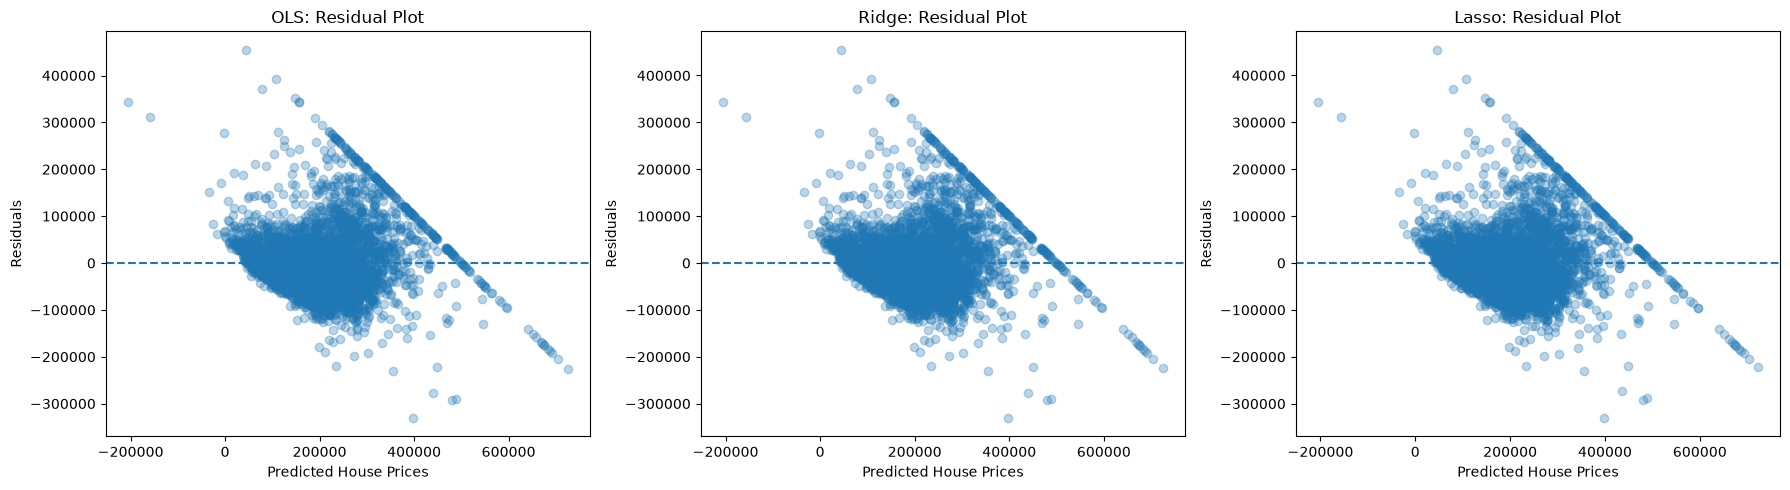

In [45]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (name, y_pred) in zip(axes, predictions.items()):
    residuals = y_test - y_pred

    ax.scatter(y_pred, residuals, alpha=0.3)
    ax.axhline(y=0, linestyle="--")

    ax.set_title(f"{name}: Residual Plot")
    ax.set_xlabel("Predicted House Prices")
    ax.set_ylabel("Residuals")

plt.tight_layout()
plt.show()

## Model Prediction and Residual Analysis

Actual vs Predicted plots were used to compare the prediction performance
of OLS, Ridge, and Lasso Regression models.

Residual plots were also examined to understand the distribution of
prediction errors.

Points closer to the diagonal line indicate more accurate predictions.
Residuals distributed randomly around zero suggest a better model fit.

These visualizations provide additional insights into model performance
beyond RMSE, MAE, and R² evaluation metrics.

In [47]:
# Select the best model based on lowest RMSE
best_index = model_comparison["RMSE"].idxmin()

best_model_name = model_comparison.loc[best_index, "Model"]

print("Best Model:", best_model_name)
print("RMSE:", model_comparison.loc[best_index, "RMSE"])
print("MAE:", model_comparison.loc[best_index, "MAE"])
print("R2 Score:", model_comparison.loc[best_index, "R2 Score"])

Best Model: OLS
RMSE: 68946.95072174494
MAE: 49586.768688246724
R2 Score: 0.6372367640362099


In [48]:
final_models = {
    "OLS": ols_model,
    "Ridge": best_ridge_model,
    "Lasso": best_lasso_model
}

final_model = final_models[best_model_name]

print(f"Selected Final Model: {best_model_name}")

Selected Final Model: OLS


## Conclusion

This project developed and evaluated three regression models:
Ordinary Least Squares (OLS), Ridge Regression, and Lasso Regression
to predict California housing prices.

Data preprocessing techniques included missing-value imputation,
feature scaling, categorical encoding, and feature engineering.

GridSearchCV was used to optimize the regularization parameters
for Ridge and Lasso Regression.

Based on the evaluation results, OLS Regression achieved
the best performance among the three models.

The OLS model achieved:
- RMSE: 68,946.95
- MAE: 49,586.77
- R² Score: 0.6372

The R² score indicates that the model explains approximately
63.72% of the variance in housing prices.

Ridge and Lasso Regression produced very similar results,
but neither outperformed OLS in this experiment.

Actual vs Predicted plots and residual analysis were also
used to evaluate prediction performance.

Overall, this project demonstrates the application of
linear regression and regularization techniques to
a real-world housing price prediction problem.

In [49]:
import joblib
import os

os.makedirs("../results", exist_ok=True)

joblib.dump(final_model, "../results/final_housing_model.pkl")
joblib.dump(preprocessor, "../results/preprocessor.pkl")

print("Final model and preprocessor saved successfully!")

Final model and preprocessor saved successfully!
